In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("Food_Delivery_Time_Prediction.csv")

In [4]:
df.head()

,Order_ID,Order_Date,Order_Hour,Day_of_Week,Is_Weekend,Is_Festival,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,...,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Average_Speed_kmph,Delivery_Priority,Time_taken_min
0,ORD000001,2025-10-28,8,Tuesday,0,0,Clear,CBD,Commercial,Scooter,...,1,Medium,23,30.55,Long,Moderate,15,28.7,Normal,91
1,ORD000002,2025-09-26,12,Friday,0,0,Rain,CBD,CBD,Scooter,...,3,Medium,11,2.25,Short,Moderate,17,23.3,Normal,21
2,ORD000003,2025-01-26,18,Sunday,1,0,Clear,Residential,Residential,Scooter,...,1,Low,31,10.15,Long,Moderate,8,28.9,Normal,52
3,ORD000004,2025-11-19,12,Wednesday,0,0,Cloudy,Residential,Industrial,Bike,...,3,Medium,19,26.33,Long,Low,9,41.4,Normal,59
4,ORD000005,2025-08-04,18,Monday,0,0,Rain,Industrial,Residential,Bike,...,1,Medium,7,30.48,Long,Moderate,8,31.7,Normal,75


In [5]:
print('Ngày bắt đầu:', df['Order_Date'].min())
print('Ngày kết thúc:', df['Order_Date'].max())

Ngày bắt đầu: 2025-01-01
Ngày kết thúc: 2025-12-31


In [6]:
df = df.drop(columns=['Order_ID'])

In [7]:
df.shape

(50000, 23)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_Date                  50000 non-null  object 
 1   Order_Hour                  50000 non-null  int64  
 2   Day_of_Week                 50000 non-null  object 
 3   Is_Weekend                  50000 non-null  int64  
 4   Is_Festival                 50000 non-null  int64  
 5   Weather                     50000 non-null  object 
 6   Pickup_Zone                 50000 non-null  object 
 7   Dropoff_Zone                50000 non-null  object 
 8   Vehicle_Type                50000 non-null  object 
 9   Rider_Experience_Years      50000 non-null  float64
 10  Rider_Rating                50000 non-null  float64
 11  Restaurant_Rating           50000 non-null  float64
 12  Cuisine_Type                50000 non-null  object 
 13  Order_Items                 500

In [9]:
df.describe()

,Order_Hour,Is_Weekend,Is_Festival,Rider_Experience_Years,Rider_Rating,Restaurant_Rating,Order_Items,Preparation_Time_Min,Road_Distance_km,Number_of_Signals,Average_Speed_kmph,Time_taken_min
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,13.847700,0.283600,0.049100,4.439744,3.951646,4.175368,2.652740,24.03118,26.201744,9.728920,31.759634,83.868980
std,5.525291,0.450749,0.216079,2.927752,0.294960,0.356201,1.590359,8.34877,12.620079,4.330849,9.510842,35.426899
min,0.000000,0.000000,0.000000,0.100000,3.200000,3.300000,1.000000,5.00000,0.080000,2.000000,8.000000,10.000000
25%,10.000000,0.000000,0.000000,2.200000,3.700000,3.900000,1.000000,18.00000,16.330000,6.000000,25.300000,58.000000
50%,14.000000,0.000000,0.000000,3.800000,3.900000,4.200000,2.000000,24.00000,25.620000,9.000000,33.100000,78.000000
75%,19.000000,1.000000,0.000000,5.900000,4.100000,4.400000,4.000000,30.00000,35.480000,14.000000,39.600000,102.000000
max,23.000000,1.000000,1.000000,15.000000,5.000000,5.000000,7.000000,51.00000,70.820000,18.000000,48.300000,180.000000


In [10]:
df.describe(include='object')

,Order_Date,Day_of_Week,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,Cuisine_Type,Restaurant_Load,Delivery_Distance_Category,Traffic_Level,Delivery_Priority
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000
unique,365,7,5,5,5,4,9,3,3,4,3
top,2025-02-12,Tuesday,Clear,Residential,Residential,Bike,North Indian,Low,Long,Low,Normal
freq,170,7264,23992,15786,16106,22943,9483,17751,47238,32567,37065


In [11]:
df.isnull().sum()

Order_Date                    0
Order_Hour                    0
Day_of_Week                   0
Is_Weekend                    0
Is_Festival                   0
Weather                       0
Pickup_Zone                   0
Dropoff_Zone                  0
Vehicle_Type                  0
Rider_Experience_Years        0
Rider_Rating                  0
Restaurant_Rating             0
Cuisine_Type                  0
Order_Items                   0
Restaurant_Load               0
Preparation_Time_Min          0
Road_Distance_km              0
Delivery_Distance_Category    0
Traffic_Level                 0
Number_of_Signals             0
Average_Speed_kmph            0
Delivery_Priority             0
Time_taken_min                0
dtype: int64

In [12]:
df.nunique()

Order_Date                     365
Order_Hour                      24
Day_of_Week                      7
Is_Weekend                       2
Is_Festival                      2
Weather                          5
Pickup_Zone                      5
Dropoff_Zone                     5
Vehicle_Type                     4
Rider_Experience_Years         129
Rider_Rating                    19
Restaurant_Rating               18
Cuisine_Type                     9
Order_Items                      7
Restaurant_Load                  3
Preparation_Time_Min            47
Road_Distance_km              5674
Delivery_Distance_Category       3
Traffic_Level                    4
Number_of_Signals               17
Average_Speed_kmph             393
Delivery_Priority                3
Time_taken_min                 170
dtype: int64

In [13]:
df.duplicated().sum()

0

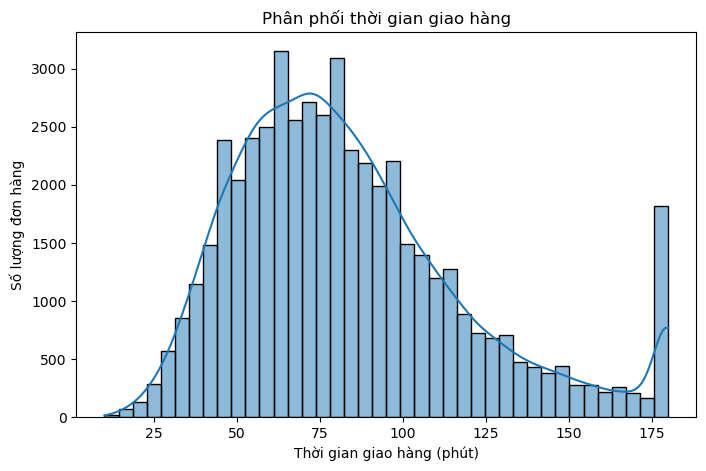

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Time_taken_min'], bins=40, kde=True)

plt.title('Phân phối thời gian giao hàng')
plt.xlabel('Thời gian giao hàng (phút)')
plt.ylabel('Số lượng đơn hàng')

plt.show()

In [15]:
corr = df.select_dtypes(include='number').corr()
print(corr['Time_taken_min'].sort_values(ascending=False))

Time_taken_min            1.000000
Road_Distance_km          0.702592
Preparation_Time_Min      0.228123
Number_of_Signals         0.127140
Is_Weekend                0.102208
Order_Items               0.081603
Is_Festival               0.073432
Order_Hour                0.033687
Restaurant_Rating         0.018994
Rider_Rating             -0.035992
Rider_Experience_Years   -0.056848
Average_Speed_kmph       -0.596058
Name: Time_taken_min, dtype: float64


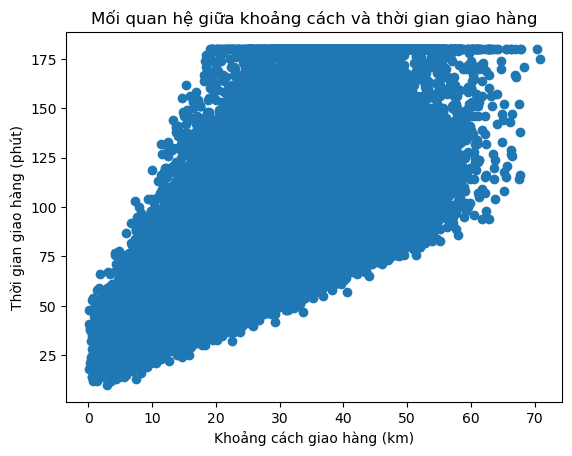

In [16]:
plt.scatter(df['Road_Distance_km'], df['Time_taken_min'])

plt.xlabel('Khoảng cách giao hàng (km)')
plt.ylabel('Thời gian giao hàng (phút)')
plt.title('Mối quan hệ giữa khoảng cách và thời gian giao hàng')

plt.show()

In [17]:
corr_distance_time = df['Road_Distance_km'].corr(df['Time_taken_min'])
print('Hệ số tương quan giữa khoảng cách và thời gian giao hàng:', corr_distance_time)

Hệ số tương quan giữa khoảng cách và thời gian giao hàng: 0.7025917986038975


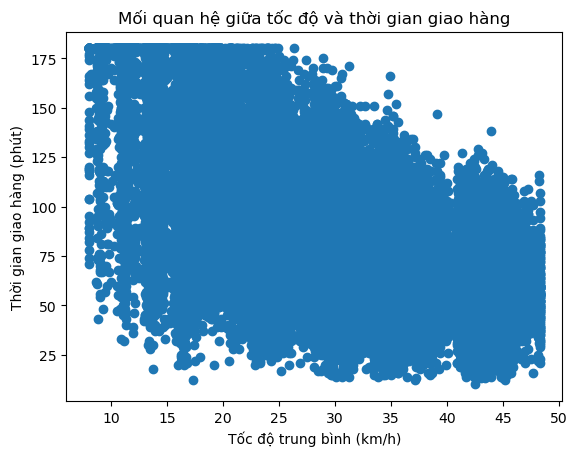

In [18]:
plt.scatter(df['Average_Speed_kmph'], df['Time_taken_min'])

plt.xlabel('Tốc độ trung bình (km/h)')
plt.ylabel('Thời gian giao hàng (phút)')
plt.title('Mối quan hệ giữa tốc độ và thời gian giao hàng')

plt.show()

In [19]:
corr_speed_time = df['Average_Speed_kmph'].corr(df['Time_taken_min'])
print('Hệ số tương quan giữa tốc độ và thời gian giao hàng:', corr_speed_time)

Hệ số tương quan giữa tốc độ và thời gian giao hàng: -0.5960583461773921


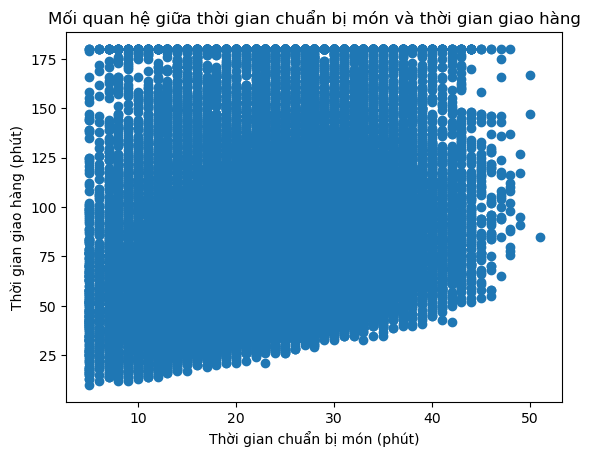

In [20]:
plt.scatter(df['Preparation_Time_Min'], df['Time_taken_min'])

plt.xlabel('Thời gian chuẩn bị món (phút)')
plt.ylabel('Thời gian giao hàng (phút)')
plt.title('Mối quan hệ giữa thời gian chuẩn bị món và thời gian giao hàng')

plt.show()

In [21]:
corr_preparation_time = df['Preparation_Time_Min'].corr(df['Time_taken_min'])
print('Hệ số tương quan giữa thời gian chuẩn bị món và thời gian giao hàng:', corr_preparation_time)

Hệ số tương quan giữa thời gian chuẩn bị món và thời gian giao hàng: 0.22812258875593017


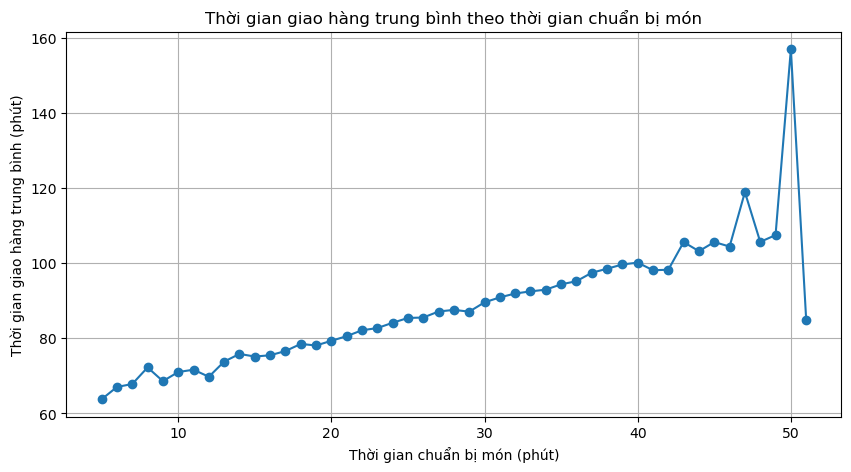

In [22]:
# Tính trung bình theo từng giá trị thời gian chuẩn bị
tg_theo_prep = df.groupby('Preparation_Time_Min')['Time_taken_min'].mean()

plt.figure(figsize=(10, 5))
plt.plot(tg_theo_prep.index, tg_theo_prep.values, marker='o')
plt.title('Thời gian giao hàng trung bình theo thời gian chuẩn bị món')
plt.xlabel('Thời gian chuẩn bị món (phút)')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.grid(True)
plt.show()

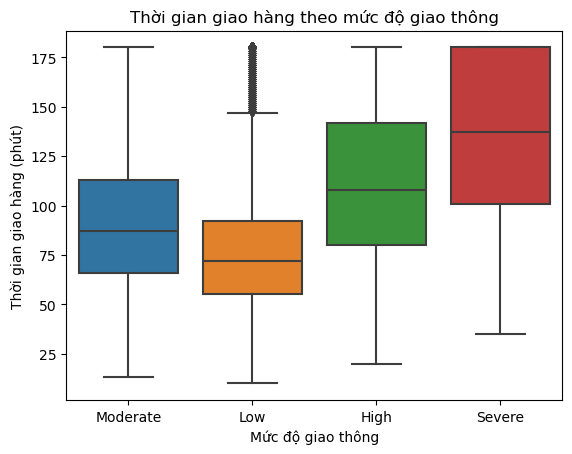

In [23]:
sns.boxplot(x='Traffic_Level', y='Time_taken_min', data=df)

plt.xlabel('Mức độ giao thông')
plt.ylabel('Thời gian giao hàng (phút)')
plt.title('Thời gian giao hàng theo mức độ giao thông')

plt.show()

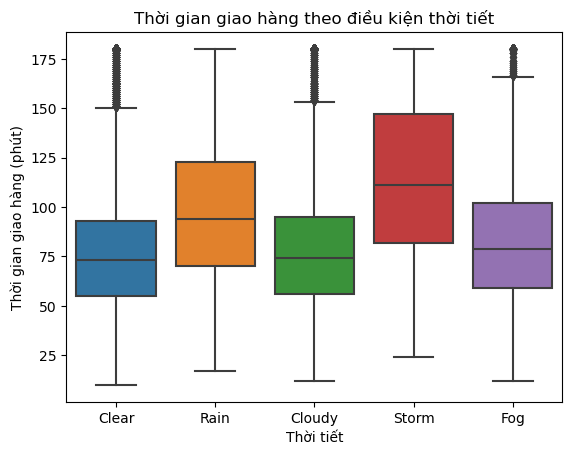

In [24]:
sns.boxplot(x='Weather', y='Time_taken_min', data=df)

plt.xlabel('Thời tiết')
plt.ylabel('Thời gian giao hàng (phút)')
plt.title('Thời gian giao hàng theo điều kiện thời tiết')

plt.show()

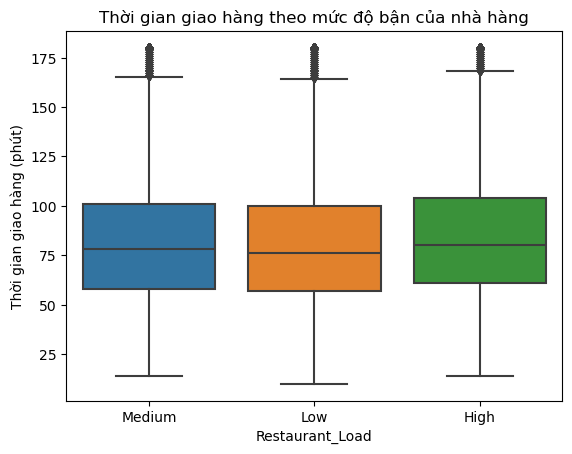

In [25]:
sns.boxplot(x='Restaurant_Load', y='Time_taken_min', data=df)

plt.xlabel('Restaurant_Load')
plt.ylabel('Thời gian giao hàng (phút)')
plt.title('Thời gian giao hàng theo mức độ bận của nhà hàng')

plt.show()

In [26]:
sorted(df['Order_Hour'].unique())

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23]

In [27]:
so_don_theo_gio = df['Order_Hour'].value_counts().sort_index()
print(so_don_theo_gio)

Order_Hour
0      463
1      471
2      463
3      507
4      490
5      956
6     1985
7     2471
8     2476
9     1982
10    1931
11    2408
12    3429
13    3905
14    2328
15    1998
16    1943
17    2463
18    3826
19    4773
20    3825
21    2394
22    1486
23    1027
Name: count, dtype: int64


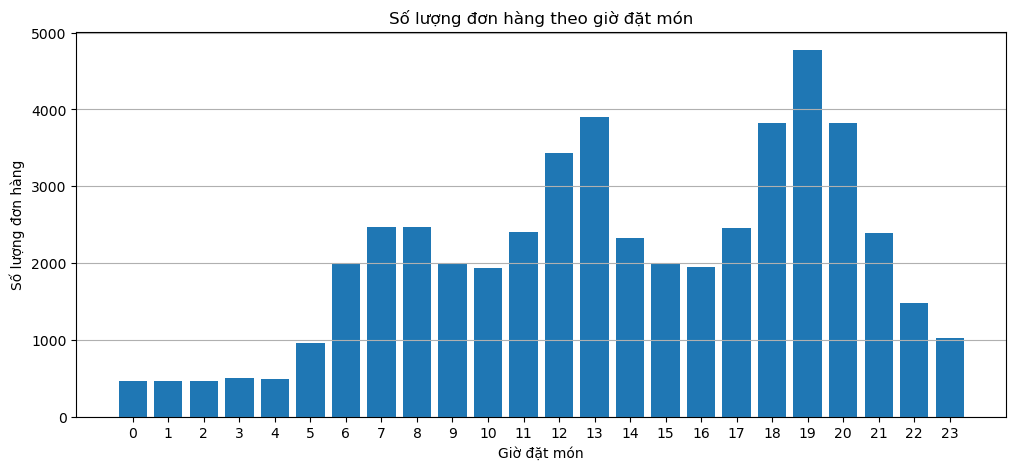

In [28]:
plt.figure(figsize=(12, 5))
plt.bar(so_don_theo_gio.index, so_don_theo_gio.values)
plt.title('Số lượng đơn hàng theo giờ đặt món')
plt.xlabel('Giờ đặt món')
plt.ylabel('Số lượng đơn hàng')
plt.xticks(range(0, 24))
plt.grid(axis='y')
plt.show()

In [29]:
tg_trung_binh_theo_gio = df.groupby('Order_Hour')['Time_taken_min'].mean()
print(tg_trung_binh_theo_gio)

Order_Hour
0     83.123110
1     80.993631
2     79.339093
3     80.735700
4     80.238776
5     80.468619
6     80.772292
7     81.497369
8     87.696284
9     87.196266
10    89.322113
11    80.768272
12    80.754156
13    81.118310
14    80.195876
15    81.645145
16    81.138960
17    81.300447
18    88.212232
19    87.826734
20    87.084183
21    86.825815
22    80.818304
23    82.879260
Name: Time_taken_min, dtype: float64


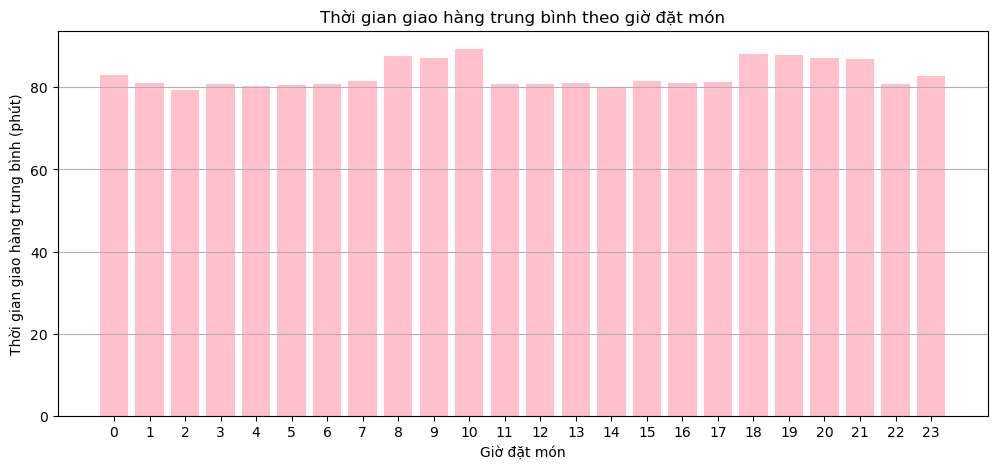

In [30]:
plt.figure(figsize=(12, 5))
plt.bar(tg_trung_binh_theo_gio.index, tg_trung_binh_theo_gio.values, color='pink')
plt.title('Thời gian giao hàng trung bình theo giờ đặt món')
plt.xlabel('Giờ đặt món')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.xticks(range(0, 24))
plt.grid(axis='y')
plt.show()

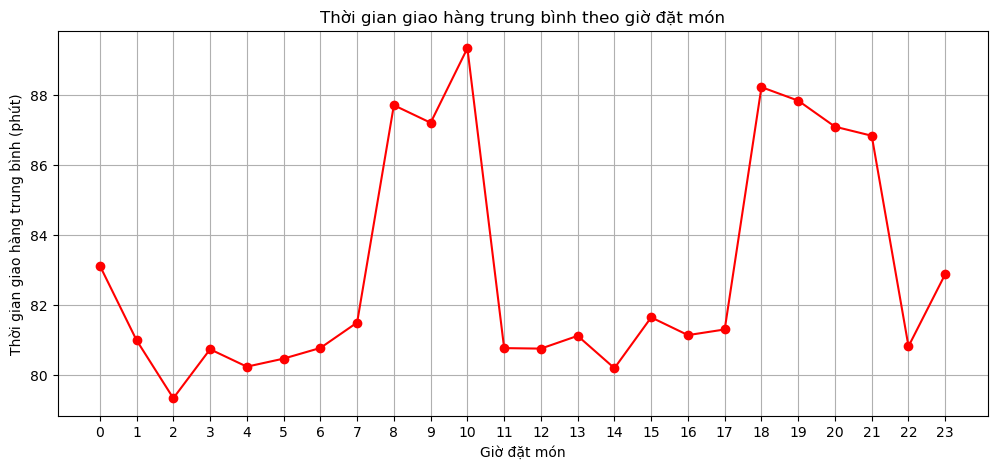

In [31]:
plt.figure(figsize=(12, 5))
plt.plot(tg_trung_binh_theo_gio.index, tg_trung_binh_theo_gio.values, 
         marker='o', color='red')
plt.title('Thời gian giao hàng trung bình theo giờ đặt món')
plt.xlabel('Giờ đặt món')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

### Tạo cột phân loại giờ cao điểm, thấp điểm

In [32]:
df['Gio_Cao_Diem'] = 'Thấp điểm'
df.loc[(df['Order_Hour'] >= 11) & (df['Order_Hour'] <= 13), 'Gio_Cao_Diem'] = 'Cao điểm'
df.loc[(df['Order_Hour'] >= 17) & (df['Order_Hour'] <= 19), 'Gio_Cao_Diem'] = 'Cao điểm'

### Tính tg giao hàng tb của 2 nhóm

In [33]:
tg_theo_gio_cao_diem = df.groupby('Gio_Cao_Diem')['Time_taken_min'].mean()
print(tg_theo_gio_cao_diem)

Gio_Cao_Diem
Cao điểm     83.883051
Thấp điểm    83.858953
Name: Time_taken_min, dtype: float64


### Tính thời gian giao hàng trung bình theo ngày trong tuần

In [34]:
tg_theo_thu = df.groupby('Day_of_Week')['Time_taken_min'].mean()
print(tg_theo_thu)

Day_of_Week
Friday       81.579291
Monday       81.368156
Saturday     89.906563
Sunday       89.350042
Thursday     82.197370
Tuesday      81.196586
Wednesday    81.618869
Name: Time_taken_min, dtype: float64


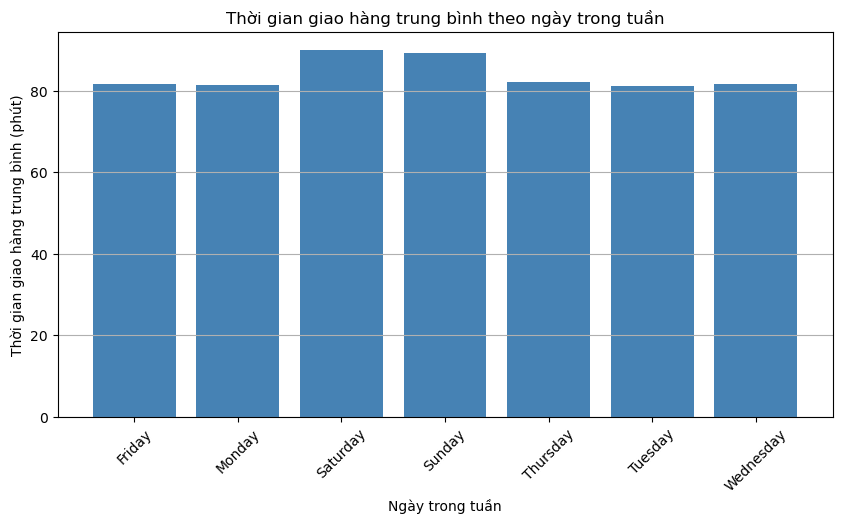

In [35]:
plt.figure(figsize=(10, 5))
plt.bar(tg_theo_thu.index, tg_theo_thu.values, color='steelblue')
plt.title('Thời gian giao hàng trung bình theo ngày trong tuần')
plt.xlabel('Ngày trong tuần')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

### Tính thời gian giao hàng trung bình theo nhóm cuối tuần / ngày thường

In [36]:
tg_cuoi_tuan = df[df['Is_Weekend'] == 1]['Time_taken_min'].mean()
tg_ngay_thuong = df[df['Is_Weekend'] == 0]['Time_taken_min'].mean()

print('Cuối tuần:', round(tg_cuoi_tuan, 2), 'phút')
print('Ngày thường:', round(tg_ngay_thuong, 2), 'phút')

Cuối tuần: 89.62 phút
Ngày thường: 81.59 phút


### thời gian giao hàng trung bình theo khu vực lấy món

In [37]:
tg_theo_pickup = df.groupby('Pickup_Zone')['Time_taken_min'].mean()
print(tg_theo_pickup)

Pickup_Zone
CBD            93.835319
Commercial     83.263782
Industrial     77.910549
Residential    80.265742
Suburban       83.271785
Name: Time_taken_min, dtype: float64


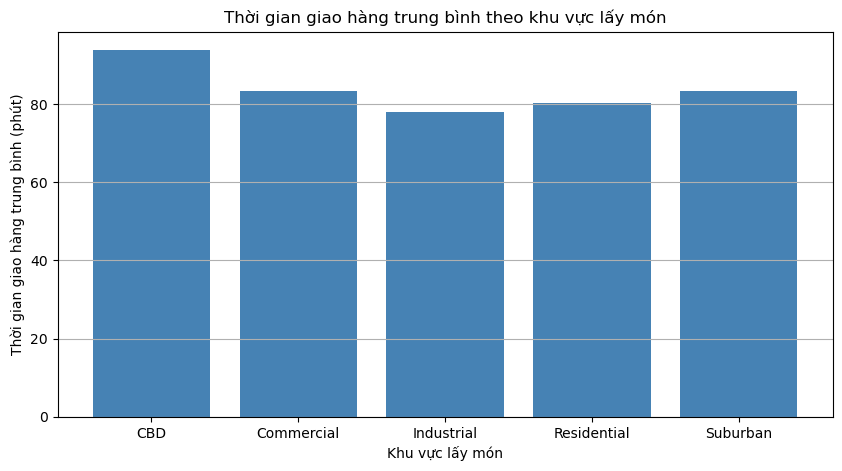

In [38]:
plt.figure(figsize=(10, 5))
plt.bar(tg_theo_pickup.index, tg_theo_pickup.values, color='steelblue')
plt.title('Thời gian giao hàng trung bình theo khu vực lấy món')
plt.xlabel('Khu vực lấy món')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.grid(axis='y')
plt.show()

### thời gian giao hàng trung bình theo khu vực giao món

In [39]:
tg_theo_dropoff = df.groupby('Dropoff_Zone')['Time_taken_min'].mean()
print(tg_theo_dropoff)

Dropoff_Zone
CBD            83.898284
Commercial     83.576403
Industrial     83.956574
Residential    83.810754
Suburban       84.306636
Name: Time_taken_min, dtype: float64


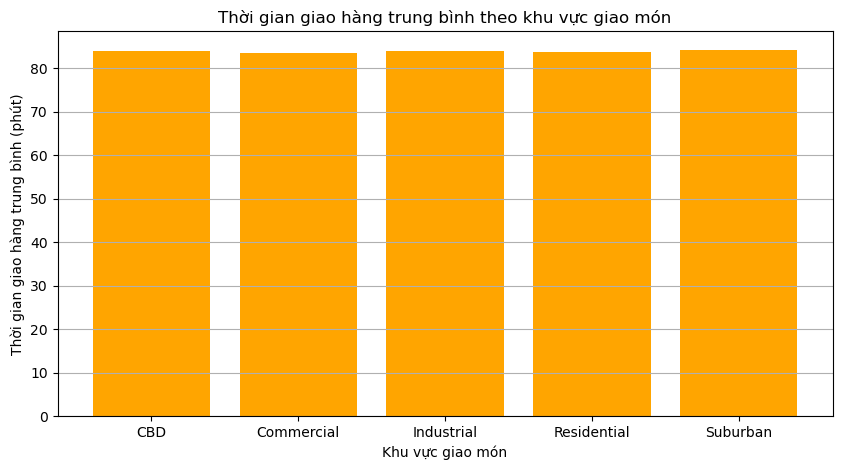

In [40]:
plt.figure(figsize=(10, 5))
plt.bar(tg_theo_dropoff.index, tg_theo_dropoff.values, color='orange')
plt.title('Thời gian giao hàng trung bình theo khu vực giao món')
plt.xlabel('Khu vực giao món')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.grid(axis='y')
plt.show()

### Tính thời gian giao hàng trung bình theo loại phương tiện

In [41]:
tg_theo_xe = df.groupby('Vehicle_Type')['Time_taken_min'].mean()
print(tg_theo_xe)

Vehicle_Type
Bicycle             130.399058
Bike                 71.948176
Electric Scooter     89.049141
Scooter              82.362156
Name: Time_taken_min, dtype: float64


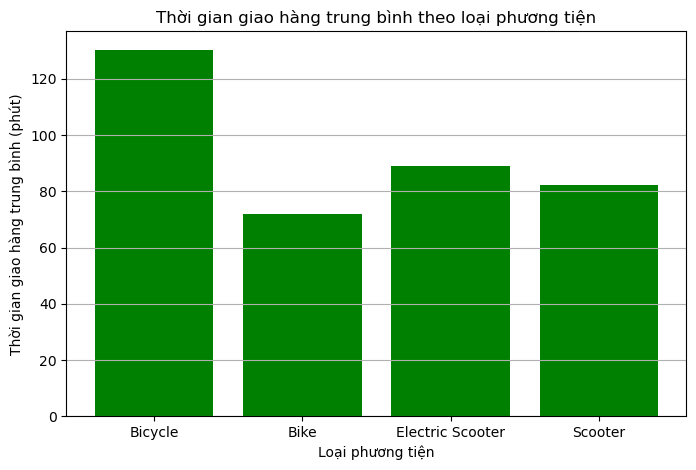

In [42]:
plt.figure(figsize=(8, 5))
plt.bar(tg_theo_xe.index, tg_theo_xe.values, color='green')
plt.title('Thời gian giao hàng trung bình theo loại phương tiện')
plt.xlabel('Loại phương tiện')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.grid(axis='y')
plt.show()

### Tính thời gian giao hàng trung bình theo mức độ ưu tiên

In [43]:
tg_theo_uu_tien = df.groupby('Delivery_Priority')['Time_taken_min'].mean()
print(tg_theo_uu_tien)

Delivery_Priority
Normal      84.171752
Priority    83.275212
VIP         82.102021
Name: Time_taken_min, dtype: float64


### Thời gian giao hàng trung bình theo mức độ bận của nhà hàng

In [44]:
tg_theo_load = df.groupby('Restaurant_Load')['Time_taken_min'].mean()
print(tg_theo_load)

Restaurant_Load
High      86.074941
Low       82.157850
Medium    83.596778
Name: Time_taken_min, dtype: float64


### Thời gian giao hàng trung bình theo loại món ăn

In [45]:
tg_theo_mon = df.groupby('Cuisine_Type')['Time_taken_min'].mean()
print(tg_theo_mon)

Cuisine_Type
Bakery          74.412655
Biryani         93.547552
Burger          73.798192
Cafe            73.942751
Chinese         85.043868
Desserts        76.010853
North Indian    89.739323
Pizza           86.559826
South Indian    80.852222
Name: Time_taken_min, dtype: float64


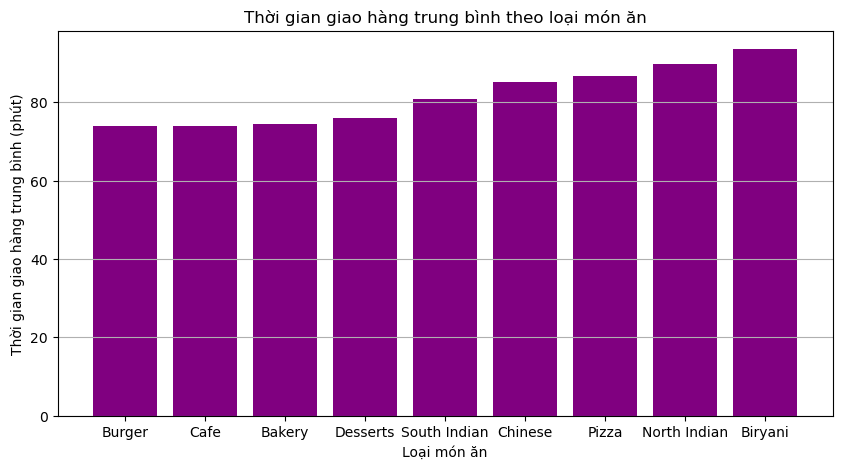

In [46]:
tg_theo_mon_sap_xep = tg_theo_mon.sort_values()

plt.figure(figsize=(10, 5))
plt.bar(tg_theo_mon_sap_xep.index, tg_theo_mon_sap_xep.values, color='purple')
plt.title('Thời gian giao hàng trung bình theo loại món ăn')
plt.xlabel('Loại món ăn')
plt.ylabel('Thời gian giao hàng trung bình (phút)')
plt.grid(axis='y')
plt.show()

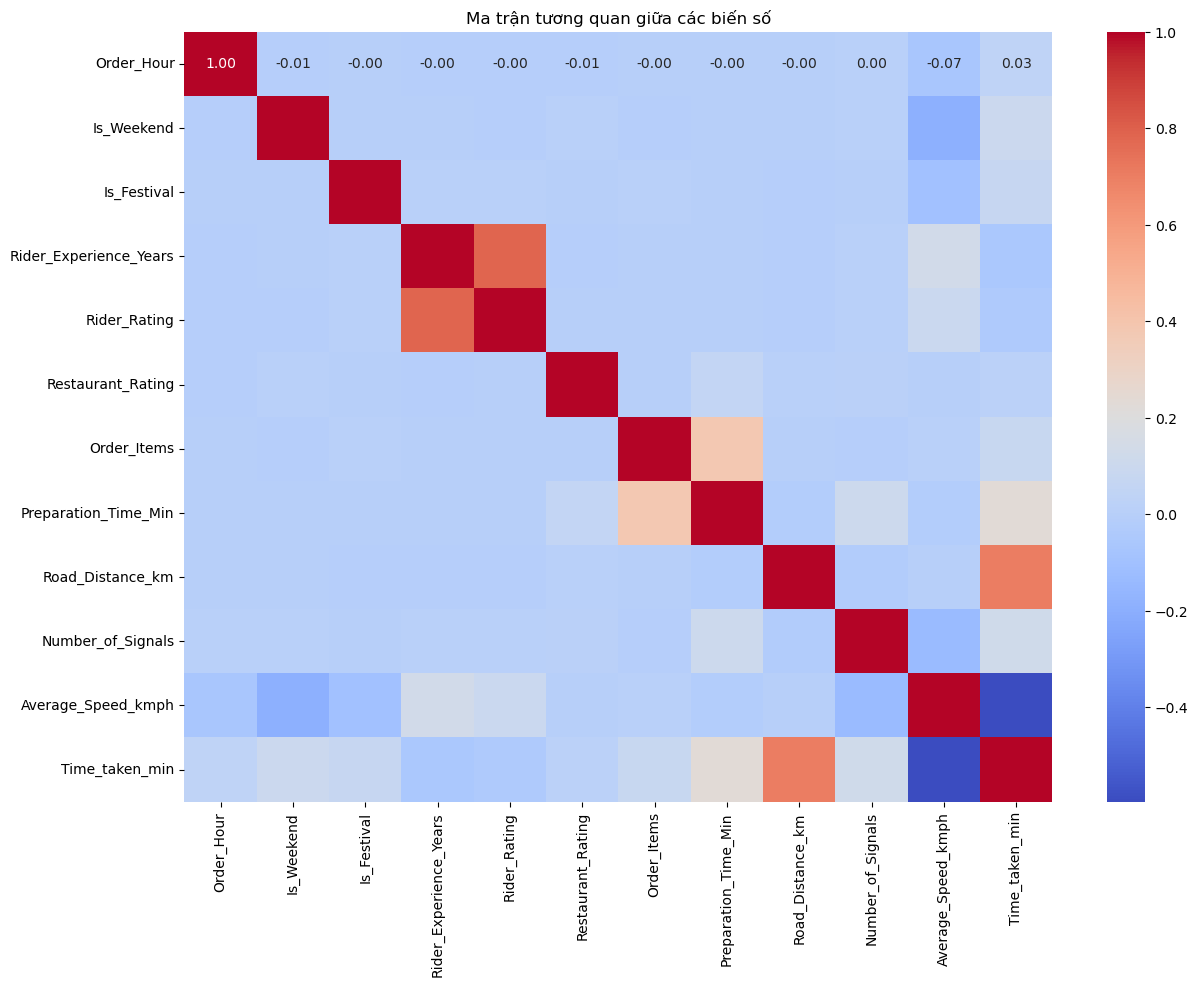

In [47]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.select_dtypes(include=['number']).corr(), 
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Ma trận tương quan giữa các biến số')
plt.show()

### Loại bỏ các biến không cần thiết

In [48]:
df = df.drop(columns=['Order_Date', 'Day_of_Week', 'Average_Speed_kmph', 'Dropoff_Zone', 'Gio_Cao_Diem'])

In [49]:
df.shape

(50000, 19)

### Đếm số đơn có thời gian giao hàng 180 phút

In [50]:
count_180 = df[df['Time_taken_min'] == 180].shape[0]

In [51]:
print("Số đơn giao 180 phút:", count_180)

Số đơn giao 180 phút: 1661


In [52]:
print("Tỷ lệ:", count_180 / len(df) * 100, "%")


Tỷ lệ: 3.322 %


### Kiểm tra giá trị âm hoặc bằng 0

In [53]:
print((df['Time_taken_min'] <= 0).sum())
print((df['Road_Distance_km'] <= 0).sum())
print((df['Preparation_Time_Min'] <= 0).sum())

0
0
0


### Kiểm tra giá trị vượt ngưỡng hợp lý

In [54]:
print((df['Preparation_Time_Min'] > 60).sum())
print((df['Road_Distance_km'] > 100).sum())

0
0


In [55]:
print("Weather:", df['Weather'].unique())
print("Pickup_Zone:", df['Pickup_Zone'].unique())
print("Vehicle_Type:", df['Vehicle_Type'].unique())
print("Cuisine_Type:", df['Cuisine_Type'].unique())
print("Delivery_Priority:", df['Delivery_Priority'].unique())
print("Traffic_Level:", df['Traffic_Level'].unique())
print("Restaurant_Load:", df['Restaurant_Load'].unique())
print("Delivery_Distance_Category:", df['Delivery_Distance_Category'].unique())

Weather: ['Clear' 'Rain' 'Cloudy' 'Storm' 'Fog']
Pickup_Zone: ['CBD' 'Residential' 'Industrial' 'Commercial' 'Suburban']
Vehicle_Type: ['Scooter' 'Bike' 'Electric Scooter' 'Bicycle']
Cuisine_Type: ['Pizza' 'Desserts' 'Biryani' 'Burger' 'South Indian' 'Bakery'
 'North Indian' 'Cafe' 'Chinese']
Delivery_Priority: ['Normal' 'VIP' 'Priority']
Traffic_Level: ['Moderate' 'Low' 'High' 'Severe']
Restaurant_Load: ['Medium' 'Low' 'High']
Delivery_Distance_Category: ['Long' 'Short' 'Medium']


In [56]:
df['Traffic_Level'] = df['Traffic_Level'].map({'Low': 0, 'Moderate': 1, 'High': 2, 'Severe': 3})
df['Restaurant_Load'] = df['Restaurant_Load'].map({'Low': 0, 'Medium': 1, 'High': 2})
df['Delivery_Distance_Category'] = df['Delivery_Distance_Category'].map({'Short': 0, 'Medium': 1, 'Long': 2})
df['Delivery_Priority'] = df['Delivery_Priority'].map({'Normal': 0, 'Priority': 1, 'VIP': 2})

### Mã hóa biến không có thứ tự (One-Hot Encoding)

In [57]:
df = pd.get_dummies(df, columns=['Weather', 'Pickup_Zone', 'Vehicle_Type', 'Cuisine_Type'], dtype=int)

In [58]:
df.shape

(50000, 38)

In [59]:
pd.set_option('display.max_columns', None)
df

,Order_Hour,Is_Weekend,Is_Festival,Rider_Experience_Years,Rider_Rating,Restaurant_Rating,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Delivery_Priority,Time_taken_min,Weather_Clear,Weather_Cloudy,Weather_Fog,Weather_Rain,Weather_Storm,Pickup_Zone_CBD,Pickup_Zone_Commercial,Pickup_Zone_Industrial,Pickup_Zone_Residential,Pickup_Zone_Suburban,Vehicle_Type_Bicycle,Vehicle_Type_Bike,Vehicle_Type_Electric Scooter,Vehicle_Type_Scooter,Cuisine_Type_Bakery,Cuisine_Type_Biryani,Cuisine_Type_Burger,Cuisine_Type_Cafe,Cuisine_Type_Chinese,Cuisine_Type_Desserts,Cuisine_Type_North Indian,Cuisine_Type_Pizza,Cuisine_Type_South Indian
0,8,0,0,3.1,3.8,3.8,1,1,23,30.55,2,1,15,0,91,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
1,12,0,0,1.8,3.6,3.9,3,1,11,2.25,0,1,17,0,21,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
2,18,1,0,3.8,3.9,4.0,1,0,31,10.15,2,1,8,0,52,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0
3,12,0,0,1.7,3.9,4.6,3,1,19,26.33,2,0,9,0,59,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0
4,18,0,0,12.4,4.4,4.0,1,1,7,30.48,2,1,8,0,75,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,14,1,0,8.4,4.4,4.0,1,1,25,33.67,2,0,4,0,94,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
49996,8,0,0,4.8,3.9,4.2,4,1,35,15.92,2,0,5,0,54,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0
49997,7,0,0,2.6,4.0,4.2,1,0,9,19.38,2,0,9,0,66,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0
49998,20,1,0,1.8,4.0,3.8,2,1,26,30.92,2,1,7,1,92,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0


### Chia tập dữ liệu

In [60]:
from sklearn.model_selection import train_test_split

### Tách biến đầu vào và biến mục tiêu

In [61]:
X = df.drop(columns=['Time_taken_min'])
y = df['Time_taken_min']

### Chia train 70% và phần còn lại 30%

In [62]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

### Chia phần còn lại thành validation (15%) và test (15%)

In [63]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [64]:
X_train

,Order_Hour,Is_Weekend,Is_Festival,Rider_Experience_Years,Rider_Rating,Restaurant_Rating,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Delivery_Priority,Weather_Clear,Weather_Cloudy,Weather_Fog,Weather_Rain,Weather_Storm,Pickup_Zone_CBD,Pickup_Zone_Commercial,Pickup_Zone_Industrial,Pickup_Zone_Residential,Pickup_Zone_Suburban,Vehicle_Type_Bicycle,Vehicle_Type_Bike,Vehicle_Type_Electric Scooter,Vehicle_Type_Scooter,Cuisine_Type_Bakery,Cuisine_Type_Biryani,Cuisine_Type_Burger,Cuisine_Type_Cafe,Cuisine_Type_Chinese,Cuisine_Type_Desserts,Cuisine_Type_North Indian,Cuisine_Type_Pizza,Cuisine_Type_South Indian
38094,16,0,0,4.6,4.0,3.8,7,2,36,37.52,2,0,6,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0
40624,7,0,0,15.0,4.7,4.5,1,1,23,36.21,2,0,13,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
49425,18,0,0,3.3,4.0,4.6,3,0,20,4.01,1,1,14,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
35734,21,0,0,7.6,4.1,4.5,1,1,24,15.95,2,0,11,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
41708,8,0,0,1.9,3.6,3.9,3,0,27,42.37,2,1,12,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,18,1,0,2.9,3.7,4.0,4,0,38,11.99,2,1,8,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0
44732,6,0,0,14.4,5.0,4.5,2,2,28,12.20,2,0,8,2,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
38158,11,0,0,3.6,3.7,4.3,1,0,7,23.73,2,0,5,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0
860,5,0,0,1.6,3.8,3.6,4,2,31,19.80,2,0,6,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1


In [85]:
X_train.shape

(35000, 37)

In [65]:
X_val.shape

(7500, 37)

In [66]:
X_test.shape

(7500, 37)

### Chuẩn hoá dữ liệu

In [67]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

### Fit trên train, transform cho cả 3 tập

In [68]:
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

## Mô hình 1: Linear Regression

In [69]:
from sklearn.linear_model import LinearRegression

In [70]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [71]:
y_pred_lr = lr.predict(X_val)

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [82]:
print("Linear Regression")
print("MAE:", round(mean_absolute_error(y_val, y_pred_lr), 2))
print("RMSE:", round(mean_squared_error(y_val, y_pred_lr) ** 0.5, 2))
print("R2:", round(r2_score(y_val, y_pred_lr), 4))

Linear Regression
MAE: 6.39
RMSE: 9.2
R2: 0.9334


## Mô hình 2: Decision Tree

In [74]:
from sklearn.tree import DecisionTreeRegressor

In [75]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [76]:
y_pred_dt = dt.predict(X_val)

In [83]:
print("Decision Tree")
print("MAE:", round(mean_absolute_error(y_val, y_pred_dt), 2))
print("RMSE:", round(mean_squared_error(y_val, y_pred_dt) ** 0.5, 2))
print("R2:", round(r2_score(y_val, y_pred_dt), 4))

Decision Tree
MAE: 4.53
RMSE: 6.15
R2: 0.9702


### Mô hình 3: Random Forest

In [78]:
from sklearn.ensemble import RandomForestRegressor

In [79]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [80]:
y_pred_rf = rf.predict(X_val)

In [84]:
print("Random Forest")
print("MAE:", round(mean_absolute_error(y_val, y_pred_rf), 2))
print("RMSE:", round(mean_squared_error(y_val, y_pred_rf) ** 0.5, 2))
print("R2:", round(r2_score(y_val, y_pred_rf), 4))

Random Forest
MAE: 3.03
RMSE: 4.06
R2: 0.987


In [86]:
y_pred_test = rf.predict(X_test)

print("Random Forest - Test")
print("MAE:", round(mean_absolute_error(y_test, y_pred_test), 2))
print("RMSE:", round(mean_squared_error(y_test, y_pred_test) ** 0.5, 2))
print("R2:", round(r2_score(y_test, y_pred_test), 4))

Random Forest - Test
MAE: 3.06
RMSE: 4.1
R2: 0.9865


### Kiểm tra overfitting

In [87]:
y_pred_train = rf.predict(X_train)

In [88]:
print("Random Forest - Train")
print("MAE:", round(mean_absolute_error(y_train, y_pred_train), 2))
print("R2:", round(r2_score(y_train, y_pred_train), 4))

Random Forest - Train
MAE: 1.15
R2: 0.9981


### Lấy độ quan trọng của từng biến

In [90]:
feature_names = df.drop(columns=['Time_taken_min']).columns

In [91]:
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf.feature_importances_
})

### Sắp xếp giảm dần


In [92]:
feature_importance = feature_importance.sort_values('importance', ascending=False)

In [93]:
print(feature_importance.head(10))

                   feature  importance
9         Road_Distance_km    0.510296
24    Vehicle_Type_Bicycle    0.221703
11           Traffic_Level    0.130703
8     Preparation_Time_Min    0.053712
25       Vehicle_Type_Bike    0.035524
18           Weather_Storm    0.017917
17            Weather_Rain    0.009615
14           Weather_Clear    0.002985
3   Rider_Experience_Years    0.002365
12       Number_of_Signals    0.002191


In [94]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Giới hạn độ sâu
rf2 = RandomForestRegressor(max_depth=10, random_state=42)
rf2.fit(X_train, y_train)

# Đánh giá train
y_pred_train2 = rf2.predict(X_train)
print("Train - MAE:", round(mean_absolute_error(y_train, y_pred_train2), 2))
print("Train - R2:", round(r2_score(y_train, y_pred_train2), 4))

# Đánh giá test
y_pred_test2 = rf2.predict(X_test)
print("Test - MAE:", round(mean_absolute_error(y_test, y_pred_test2), 2))
print("Test - R2:", round(r2_score(y_test, y_pred_test2), 4))

Train - MAE: 3.89
Train - R2: 0.9791
Test - MAE: 4.34
Test - R2: 0.9729


### Lấy tên top 5 biến

In [95]:
top_features = feature_importance.head(5)['feature'].tolist()
print(top_features)

['Road_Distance_km', 'Vehicle_Type_Bicycle', 'Traffic_Level', 'Preparation_Time_Min', 'Vehicle_Type_Bike']


In [96]:
# Lấy dữ liệu gốc từ df
X_new = df[top_features]
y_new = df['Time_taken_min']

print(X_new.shape)

(50000, 5)


In [97]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_new, test_size=0.2, random_state=42
)

print(X_train_new.shape)
print(X_test_new.shape)

(40000, 5)
(10000, 5)


In [98]:
rf_new = RandomForestRegressor(random_state=42)
rf_new.fit(X_train_new, y_train_new)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [99]:
y_pred_new = rf_new.predict(X_test_new)

In [100]:
print("Random Forest (top 5 biến) - Test")
print("MAE:", round(mean_absolute_error(y_test_new, y_pred_new), 2))
print("RMSE:", round(mean_squared_error(y_test_new, y_pred_new) ** 0.5, 2))
print("R2:", round(r2_score(y_test_new, y_pred_new), 4))

Random Forest (top 5 biến) - Test
MAE: 6.52
RMSE: 9.25
R2: 0.9326
